# Studi Komparatif Model Generatif: AE, Sparse AE, VAE, GAN, DCGAN, DDPM + Batasan MLP Classifier
Seluruh kode ada di notebook ini (tanpa file tambahan). **Aktifkan GPU:** Runtime > Change runtime type > T4 GPU. Jalankan sel dari atas ke bawah.

## 0. Instalasi & cek GPU

In [1]:
!pip install -q torchmetrics torch-fidelity matplotlib
import torch; print(torch.__version__, 'CUDA:', torch.cuda.is_available())

2.14.1+cu130 CUDA: True


## 1. Utilitas: seed, data split 80/10/10, metrik (MSE/PSNR/SSIM), FID, latency

In [2]:
"""Utilitas bersama: seed, data split 80/10/10, metrik, FID, latency."""
import random, time
import numpy as np, torch
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, ConcatDataset, random_split
from torchmetrics.functional import peak_signal_noise_ratio as _psnr
from torchmetrics.functional import structural_similarity_index_measure as _ssim

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DS = {"fashion": torchvision.datasets.FashionMNIST, "mnist": torchvision.datasets.MNIST,
      "kmnist": torchvision.datasets.KMNIST, "cifar10": torchvision.datasets.CIFAR10}


def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def get_data(name="fashion", bs=128, root="./data"):
    cls, tf = DS[name], T.ToTensor()            # piksel dalam [0,1]
    full = ConcatDataset([cls(root, train=True, download=True, transform=tf),
                          cls(root, train=False, download=True, transform=tf)])
    n = len(full); n_tr = int(.8 * n); n_va = int(.1 * n)
    g = torch.Generator().manual_seed(42)
    tr, va, te = random_split(full, [n_tr, n_va, n - n_tr - n_va], generator=g)
    mk = lambda d, s: DataLoader(d, batch_size=bs, shuffle=s, num_workers=2, drop_last=False)
    C, H, W = tr[0][0].shape
    return mk(tr, True), mk(va, False), mk(te, False), dict(C=C, H=H, W=W, D=C * H * W)


def collect(loader):
    xs, ys = zip(*[(x, y) for x, y in loader])
    return torch.cat(xs), torch.cat(ys)


@torch.no_grad()
def recon_metrics(fn, loader):
    """fn: x -> x_hat (keduanya [0,1]). Mengembalikan MSE, PSNR(dB), SSIM pada seluruh loader."""
    se = ps = ss = n = 0
    for x, _ in loader:
        x = x.to(DEV); r = fn(x).clamp(0, 1); b = x.size(0)
        se += ((r - x) ** 2).mean((1, 2, 3)).sum().item()
        ps += _psnr(r, x, data_range=1.0, reduction="none", dim=(1, 2, 3)).sum().item()
        ss += _ssim(r, x, data_range=1.0).item() * b
        n += b
    return dict(mse=se / n, psnr=ps / n, ssim=ss / n)


@torch.no_grad()
def anomaly_auroc(fn, loader):
    """Anomali sintetis: patch putih 8x8 di tengah. Skor = reconstruction MSE per citra."""
    from torchmetrics.functional.classification import binary_auroc
    sc, lb = [], []
    for x, _ in loader:
        x = x.to(DEV); xa = x.clone(); h = x.shape[-1] // 2
        xa[:, :, h - 4:h + 4, h - 4:h + 4] = 1.0
        for inp, l in ((x, 0), (xa, 1)):
            e = ((fn(inp) - inp) ** 2).flatten(1).mean(1)
            sc.append(e.cpu()); lb.append(torch.full((len(e),), l))
    return binary_auroc(torch.cat(sc), torch.cat(lb)).item()


def _to3(x):
    return x.repeat(1, 3, 1, 1) if x.shape[1] == 1 else x


@torch.no_grad()
def fid_score(test_loader, gen_fn, n, bs=250):
    """gen_fn(b) -> citra [0,1]. FID terhadap Test Set."""
    from torchmetrics.image.fid import FrechetInceptionDistance
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(DEV)
    for x, _ in test_loader:
        fid.update(_to3(x.to(DEV)), real=True)
    done = 0
    while done < n:
        b = min(bs, n - done)
        fid.update(_to3(gen_fn(b).clamp(0, 1)), real=False); done += b
    return fid.compute().item()


@torch.no_grad()
def latency_ms(fn, reps=20, warm=3):
    for _ in range(warm if reps > 1 else 0):
        fn()
    sync(); t = time.perf_counter()
    for _ in range(reps):
        fn()
    sync()
    return (time.perf_counter() - t) / reps * 1000

## 2. Arsitektur: AE, VAE, Vanilla GAN, DCGAN, UNet+Diffusion (DDPM), MLP Classifier

In [3]:
"""Arsitektur: AE (vanilla/sparse), VAE, Vanilla GAN, DCGAN, DDPM (UNet), MLP Classifier."""
import math, torch, torch.nn as nn, torch.nn.functional as F


class AE(nn.Module):
    """784 -> 256 (h, lapisan jarang) -> z(64) -> 256 -> 784. Vanilla & Sparse memakai arsitektur identik."""
    def __init__(s, D, shape, zd=64, hd=256):
        super().__init__(); s.shape = shape
        s.e1 = nn.Linear(D, hd); s.e2 = nn.Linear(hd, zd)
        s.d1 = nn.Linear(zd, hd); s.d2 = nn.Linear(hd, D)
    def encode(s, x):
        h = F.relu(s.e1(x.flatten(1))); return s.e2(h), h
    def decode(s, z):
        return torch.sigmoid(s.d2(F.relu(s.d1(z)))).view(-1, *s.shape)
    def forward(s, x):
        z, h = s.encode(x); return s.decode(z), z, h


class VAE(nn.Module):
    def __init__(s, D, shape, zd=64):
        super().__init__(); s.shape, s.zd = shape, zd
        s.enc = nn.Sequential(nn.Linear(D, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        s.mu = nn.Linear(256, zd); s.lv = nn.Linear(256, zd)
        s.dec = nn.Sequential(nn.Linear(zd, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(), nn.Linear(512, D), nn.Sigmoid())
    def encode(s, x):
        h = s.enc(x.flatten(1)); return s.mu(h), s.lv(h)
    def decode(s, z): return s.dec(z).view(-1, *s.shape)
    def forward(s, x):
        mu, lv = s.encode(x); z = mu + torch.randn_like(mu) * (0.5 * lv).exp()
        return s.decode(z), mu, lv


class GenMLP(nn.Module):
    def __init__(s, D, shape, zd=100):
        super().__init__(); s.shape, s.zd = shape, zd
        s.net = nn.Sequential(nn.Linear(zd, 256), nn.LeakyReLU(.2), nn.Linear(256, 512), nn.LeakyReLU(.2),
                              nn.Linear(512, 1024), nn.LeakyReLU(.2), nn.Linear(1024, D), nn.Tanh())
    def forward(s, z): return s.net(z).view(-1, *s.shape)          # [-1,1]


class DiscMLP(nn.Module):
    def __init__(s, D):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(D, 1024), nn.LeakyReLU(.2), nn.Dropout(.3), nn.Linear(1024, 512), nn.LeakyReLU(.2),
                              nn.Dropout(.3), nn.Linear(512, 256), nn.LeakyReLU(.2), nn.Linear(256, 1))
    def forward(s, x): return s.net(x.flatten(1)).squeeze(1)       # logit


class GenConv(nn.Module):
    def __init__(s, C, H, zd=100):
        super().__init__(); s.zd = zd; k = H // 4
        s.net = nn.Sequential(nn.ConvTranspose2d(zd, 256, k, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
                              nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
                              nn.ConvTranspose2d(128, C, 4, 2, 1), nn.Tanh())
    def forward(s, z): return s.net(z.view(z.size(0), -1, 1, 1))


class DiscConv(nn.Module):
    def __init__(s, C, H):
        super().__init__(); k = H // 4
        s.net = nn.Sequential(nn.Conv2d(C, 64, 4, 2, 1), nn.LeakyReLU(.2, True),
                              nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(.2, True),
                              nn.Conv2d(128, 1, k, 1, 0))
    def forward(s, x): return s.net(x).flatten()


def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0, .02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1, .02); nn.init.zeros_(m.bias)


# ---------------- DDPM ----------------
class SinEmb(nn.Module):
    def __init__(s, d): super().__init__(); s.d = d
    def forward(s, t):
        half = s.d // 2
        f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        a = t[:, None].float() * f[None]; return torch.cat([a.sin(), a.cos()], -1)


class Res(nn.Module):
    def __init__(s, i, o, td):
        super().__init__()
        s.n1 = nn.GroupNorm(8, i); s.c1 = nn.Conv2d(i, o, 3, padding=1); s.t = nn.Linear(td, o)
        s.n2 = nn.GroupNorm(8, o); s.c2 = nn.Conv2d(o, o, 3, padding=1)
        s.sk = nn.Conv2d(i, o, 1) if i != o else nn.Identity()
    def forward(s, x, te):
        h = s.c1(F.silu(s.n1(x))) + s.t(te)[:, :, None, None]
        return s.c2(F.silu(s.n2(h))) + s.sk(x)


class UNet(nn.Module):
    def __init__(s, C=1, b=64, td=128):
        super().__init__()
        s.te = nn.Sequential(SinEmb(b), nn.Linear(b, td), nn.SiLU(), nn.Linear(td, td))
        s.inc = nn.Conv2d(C, b, 3, padding=1)
        s.r0 = Res(b, b, td); s.dn1 = nn.Conv2d(b, b, 3, 2, 1)
        s.r1 = Res(b, 2 * b, td); s.dn2 = nn.Conv2d(2 * b, 2 * b, 3, 2, 1)
        s.m1 = Res(2 * b, 2 * b, td); s.m2 = Res(2 * b, 2 * b, td)
        s.u1 = Res(4 * b, 2 * b, td); s.u0 = Res(3 * b, b, td)
        s.out = nn.Sequential(nn.GroupNorm(8, b), nn.SiLU(), nn.Conv2d(b, C, 3, padding=1))
    def forward(s, x, t):
        te = s.te(t); h0 = s.r0(s.inc(x), te); h1 = s.r1(s.dn1(h0), te)
        m = s.m2(s.m1(s.dn2(h1), te), te)
        up = lambda a: F.interpolate(a, scale_factor=2, mode="nearest")
        u1 = s.u1(torch.cat([up(m), h1], 1), te); u0 = s.u0(torch.cat([up(u1), h0], 1), te)
        return s.out(u0)


class Diffusion:
    def __init__(s, T=1000, dev="cpu"):
        s.T = T; s.b = torch.linspace(1e-4, 0.02, T, device=dev); s.a = 1 - s.b; s.ab = torch.cumprod(s.a, 0)
    def loss(s, net, x0):                                   # x0 di [-1,1]
        t = torch.randint(0, s.T, (x0.size(0),), device=x0.device); e = torch.randn_like(x0)
        ab = s.ab[t][:, None, None, None]
        return F.mse_loss(net(ab.sqrt() * x0 + (1 - ab).sqrt() * e, t), e)
    @torch.no_grad()
    def sample(s, net, n, shape, traj=0):
        x = torch.randn(n, *shape, device=s.b.device); frames = []
        for i in reversed(range(s.T)):
            t = torch.full((n,), i, device=x.device, dtype=torch.long)
            eps = net(x, t)
            x = (x - s.b[i] / (1 - s.ab[i]).sqrt() * eps) / s.a[i].sqrt()
            if i > 0: x = x + s.b[i].sqrt() * torch.randn_like(x)
            if traj and (i % max(1, s.T // traj) == 0 or i == 0): frames.append(((x + 1) / 2).clamp(0, 1)[:8].cpu())
        out = ((x + 1) / 2).clamp(0, 1)
        return (out, frames) if traj else out


class MLPClassifier(nn.Module):
    def __init__(s, D, nc=10):
        super().__init__(); s.l1 = nn.Linear(D, 256); s.l2 = nn.Linear(256, 64); s.l3 = nn.Linear(64, nc)
    def features(s, x): return F.relu(s.l2(F.relu(s.l1(x.flatten(1)))))     # z_MLP in R^64
    def forward(s, x): return s.l3(s.features(x))

## 3. Training loops

In [4]:
"""Loop training tiap model. Setiap fungsi mengembalikan history dict (loss per epoch + waktu per epoch)."""
import time, copy, torch, torch.nn.functional as F


def _H(): return {"loss": [], "val": [], "time": []}


def train_ae(m, tr, va, epochs, lam=0.0, lr=1e-3):
    opt = torch.optim.Adam(m.parameters(), lr); H = _H(); m.to(DEV)
    for ep in range(epochs):
        m.train(); sync(); t0 = time.time(); L = []
        for x, _ in tr:
            x = x.to(DEV); r, z, h = m(x)
            loss = F.mse_loss(r, x) + lam * h.abs().mean()      # MSE + lambda*||h||_1 (rata-rata)
            opt.zero_grad(); loss.backward(); opt.step(); L.append(loss.item())
        sync(); H["time"].append(time.time() - t0); H["loss"].append(sum(L) / len(L))
        m.eval()
        with torch.no_grad(): H["val"].append(sum(F.mse_loss(m(x.to(DEV))[0], x.to(DEV)).item() for x, _ in va) / len(va))
        print(f"[AE lam={lam}] ep{ep+1} loss={H['loss'][-1]:.5f} val_mse={H['val'][-1]:.5f}")
    return H


def train_vae(m, tr, va, epochs, lr=1e-3):
    opt = torch.optim.Adam(m.parameters(), lr); H = _H(); m.to(DEV)
    def elbo(x):
        r, mu, lv = m(x); B = x.size(0)
        bce = F.binary_cross_entropy(r, x, reduction="sum") / B
        kl = -0.5 * torch.sum(1 + lv - mu ** 2 - lv.exp()) / B
        return bce + kl
    for ep in range(epochs):
        m.train(); sync(); t0 = time.time(); L = []
        for x, _ in tr:
            loss = elbo(x.to(DEV)); opt.zero_grad(); loss.backward(); opt.step(); L.append(loss.item())
        sync(); H["time"].append(time.time() - t0); H["loss"].append(sum(L) / len(L))
        m.eval()
        with torch.no_grad(): H["val"].append(sum(elbo(x.to(DEV)).item() for x, _ in va) / len(va))
        print(f"[VAE] ep{ep+1} -ELBO={H['loss'][-1]:.2f} val={H['val'][-1]:.2f}")
    return H


def train_gan(G, D, tr, epochs, tag="GAN", lr=2e-4):
    G.to(DEV); D.to(DEV)
    oG = torch.optim.Adam(G.parameters(), lr, betas=(.5, .999)); oD = torch.optim.Adam(D.parameters(), lr, betas=(.5, .999))
    bce = F.binary_cross_entropy_with_logits; H = {"G": [], "D": [], "time": []}
    for ep in range(epochs):
        G.train(); D.train(); sync(); t0 = time.time(); lg = ld = n = 0
        for x, _ in tr:
            x = x.to(DEV) * 2 - 1; B = x.size(0); one, zero = torch.ones(B, device=DEV), torch.zeros(B, device=DEV)
            fake = G(torch.randn(B, G.zd, device=DEV))
            dl = bce(D(x), one) + bce(D(fake.detach()), zero)
            oD.zero_grad(); dl.backward(); oD.step()
            gl = bce(D(fake), one)                                  # non-saturating generator loss
            oG.zero_grad(); gl.backward(); oG.step()
            lg += gl.item(); ld += dl.item(); n += 1
        sync(); H["time"].append(time.time() - t0); H["G"].append(lg / n); H["D"].append(ld / n)
        print(f"[{tag}] ep{ep+1} G={H['G'][-1]:.3f} D={H['D'][-1]:.3f}")
    return H


def train_ddpm(net, diff, tr, epochs, lr=2e-4, ema_decay=0.999):
    net.to(DEV); opt = torch.optim.Adam(net.parameters(), lr); ema = copy.deepcopy(net).eval(); H = _H()
    for ep in range(epochs):
        net.train(); sync(); t0 = time.time(); L = []
        for x, _ in tr:
            loss = diff.loss(net, x.to(DEV) * 2 - 1)
            opt.zero_grad(); loss.backward(); opt.step(); L.append(loss.item())
            with torch.no_grad():
                for pe, p in zip(ema.parameters(), net.parameters()): pe.mul_(ema_decay).add_(p, alpha=1 - ema_decay)
        sync(); H["time"].append(time.time() - t0); H["loss"].append(sum(L) / len(L))
        print(f"[DDPM] ep{ep+1} eps-loss={H['loss'][-1]:.5f}")
    return ema, H

## 4. Fungsi visualisasi

In [5]:
import matplotlib
import matplotlib.pyplot as plt, torch
from torchvision.utils import make_grid


def show(ax, imgs, nrow, title=""):
    g = make_grid(imgs.detach().cpu().clamp(0, 1), nrow=nrow, padding=1, pad_value=1).permute(1, 2, 0).numpy()
    ax.imshow(g); ax.axis("off"); ax.set_title(title, fontsize=9)

## 5. Konfigurasi
Ganti `QUICK = False` untuk run penuh.

In [6]:
from types import SimpleNamespace
QUICK = True   # True = uji cepat (beberapa menit). Ubah ke False untuk run penuh (hasil laporan).

if QUICK:
    CFG_MLP = SimpleNamespace(dataset="fashion", epochs=3)
    CFG_GEN = SimpleNamespace(dataset="fashion", bs=128, ep_ae=2, ep_vae=2, ep_gan=2, ep_dcgan=2, ep_ddpm=2,
                              T=100, lam=1e-2, zd=64, fid_n=500)
else:
    CFG_MLP = SimpleNamespace(dataset="fashion", epochs=30)
    CFG_GEN = SimpleNamespace(dataset="fashion", bs=128, ep_ae=30, ep_vae=30, ep_gan=50, ep_dcgan=30, ep_ddpm=30,
                              T=1000, lam=1e-2, zd=64, fid_n=0)   # fid_n=0 -> seukuran test set
print(CFG_MLP, CFG_GEN)

namespace(dataset='fashion', epochs=3) namespace(dataset='fashion', bs=128, ep_ae=2, ep_vae=2, ep_gan=2, ep_dcgan=2, ep_ddpm=2, T=100, lam=0.01, zd=64, fid_n=500)


## 6. Bagian 2 tugas: pembuktian batasan MLP Classifier (Tahap 1-5) + Figur 3

In [8]:
"""Bagian 2: pembuktian empiris batasan MLP Classifier untuk image generation (Tahap 1-5) + Figur 3."""
import argparse, json, os, torch, torch.nn as nn, torch.nn.functional as F, matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

a = CFG_MLP; os.makedirs("outputs", exist_ok=True); set_seed(42)
tr, va, te, I = get_data(a.dataset); D = I["D"]; shape = (I["C"], I["H"], I["W"])
R = {}

# Tahap 1: latih MLP classifier 784-256-64-10
clf = MLPClassifier(D).to(DEV); opt = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(a.epochs):
    clf.train()
    for x, y in tr:
        loss = F.cross_entropy(clf(x.to(DEV)), y.to(DEV)); opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
with torch.no_grad(): acc = sum((clf(x.to(DEV)).argmax(1).cpu() == y).sum().item() for x, y in te) / len(te.dataset)
R["test_acc"] = acc; print("Test acc:", acc); assert acc >= 0.85, "Akurasi < 85%: naikkan --epochs atau ganti dataset"
for q in clf.parameters(): q.requires_grad_(False)
# Torch Linear menyimpan W sebagai (out,in) dan forward = x @ W^T. Maka operasi "W^T v" (kolom) = v_row @ W_torch.
W1, W2, W3 = clf.l1.weight, clf.l2.weight, clf.l3.weight

xs, ys = collect(te); idx = [(ys == c).nonzero()[0].item() for c in range(10)]; xc = xs[idx].to(DEV)

# Tahap 2: proyeksi balik one-hot kelas
with torch.no_grad():
    y1 = torch.eye(10, device=DEV); zh = F.relu(y1 @ W3); h1 = F.relu(zh @ W2); x_td = torch.sigmoid(h1 @ W1).view(-1, *shape)
    # Tahap 3: proyeksi balik latent z_MLP citra uji
    z = clf.features(xc); x_lt = torch.sigmoid(F.relu(z @ W2) @ W1).view(-1, *shape)
R["mse_topdown_vs_class_sample"] = F.mse_loss(x_td, xc).item(); R["mse_latent_transpose"] = F.mse_loss(x_lt, xc).item()

# Tahap 4: frozen latent decoder vs Vanilla AE (z=64)
dec = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, D), nn.Sigmoid()).to(DEV); od = torch.optim.Adam(dec.parameters(), 1e-3)
for ep in range(a.epochs):
    for x, _ in tr:
        x = x.to(DEV)
        with torch.no_grad(): zz = clf.features(x)
        loss = F.mse_loss(dec(zz), x.flatten(1)); od.zero_grad(); loss.backward(); od.step()
dec.eval(); fdec = lambda x: dec(clf.features(x)).view(-1, *shape)
R["frozen_decoder_z_MLP"] = recon_metrics(fdec, te)
set_seed(42); ae = AE(D, shape, 64); train_ae(ae, tr, va, a.epochs); ae.eval()
R["vanilla_ae_z64"] = recon_metrics(lambda x: ae(x)[0], te)

# Tahap 5: sampling prior N(mu_z, diag(sigma_z^2)) pada ruang laten klasifier
with torch.no_grad():
    Zt = torch.cat([clf.features(x.to(DEV)) for x, _ in te]); mu, sd = Zt.mean(0), Zt.std(0)
    zr = mu + sd * torch.randn(16, 64, device=DEV); x_s = dec(zr).view(-1, *shape)
    R["frac_z_zero_(ReLU)"] = (Zt == 0).float().mean().item()
json.dump(R, open("outputs/mlp_limits.json", "w"), indent=2); print(json.dumps(R, indent=2))

# Figur 3 (empat panel)
with torch.no_grad(): rec_mlp, rec_ae = fdec(xc), ae(xc)[0]
fig, axs = plt.subplots(4, 1, figsize=(8, 13))
show(axs[0], xc, 10, "(1) Citra asli (satu per kelas)")
show(axs[1], torch.cat([x_td, x_lt]), 10, "(2) Baris atas: W^T dari one-hot kelas | Baris bawah: W^T dari z_MLP")
show(axs[2], torch.cat([xc, rec_mlp, rec_ae]), 10, "(3) Asli | Frozen decoder z_MLP | Vanilla AE z_AE")
show(axs[3], x_s, 8, "(4) Sampling z ~ N(mu_z, diag(sigma_z^2)) -> decoder beku")
fig.savefig("outputs/fig3_mlp_limits.png", dpi=200, bbox_inches="tight")

Test acc: 0.8724285714285714


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `peak_signal_noise_ratio` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `peak_signal_noise_ratio` from `torchmetrics.image` instead.
  _future_warning(
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


[AE lam=0.0] ep1 loss=0.03181 val_mse=0.01862
[AE lam=0.0] ep2 loss=0.01654 val_mse=0.01559
[AE lam=0.0] ep3 loss=0.01394 val_mse=0.01325
{
  "test_acc": 0.8724285714285714,
  "mse_topdown_vs_class_sample": 0.156087726354599,
  "mse_latent_transpose": 0.22932754456996918,
  "frozen_decoder_z_MLP": {
    "mse": 0.0208210654599326,
    "psnr": 17.390414829799106,
    "ssim": 0.6331782267434256
  },
  "vanilla_ae_z64": {
    "mse": 0.013210289938109262,
    "psnr": 19.5406519077846,
    "ssim": 0.7486335079329355
  },
  "frac_z_zero_(ReLU)": 0.4682410657405853
}


## 7. Studi komparatif 6 model: training, metrik, FID, latency, Figur 1, 2, 4, 5 + tabel

In [9]:
"""Studi komparatif 6 model generatif. Output: outputs/results.json, tabel markdown, Figur 1,2,4,5."""
import argparse, json, os, torch, matplotlib
import matplotlib.pyplot as plt

a = CFG_GEN
os.makedirs("outputs", exist_ok=True); set_seed(42)
tr, va, te, I = get_data(a.dataset, a.bs); C, Hh, D = I["C"], I["H"], I["D"]; shape = (C, Hh, I["W"])
R, HIST = {}, {}
fid_n = a.fid_n or len(te.dataset)
Z = lambda b, d: torch.randn(b, d, device=DEV)
tm = lambda H: sum(H["time"]) / len(H["time"])

# ---- Training ----
set_seed(42); ae = AE(D, shape, a.zd); HIST["Vanilla AE"] = train_ae(ae, tr, va, a.ep_ae, 0.0)
set_seed(42); sae = AE(D, shape, a.zd); HIST["Sparse AE"] = train_ae(sae, tr, va, a.ep_ae, a.lam)
set_seed(42); vae = VAE(D, shape, a.zd); HIST["VAE"] = train_vae(vae, tr, va, a.ep_vae)
set_seed(42); gG, gD = GenMLP(D, shape), DiscMLP(D); HIST["Vanilla GAN"] = train_gan(gG, gD, tr, a.ep_gan, "GAN")
set_seed(42); dG, dD = GenConv(C, Hh), DiscConv(C, Hh); dG.apply(dcgan_init); dD.apply(dcgan_init)
HIST["DCGAN"] = train_gan(dG, dD, tr, a.ep_dcgan, "DCGAN")
set_seed(42); diff = Diffusion(a.T, DEV); ddpm, HIST["DDPM"] = train_ddpm(UNet(C), diff, tr, a.ep_ddpm)
for m in (ae, sae, vae, gG, dG, ddpm): m.eval()
torch.save({k: m.state_dict() for k, m in dict(ae=ae, sae=sae, vae=vae, gG=gG, dG=dG, ddpm=ddpm).items()}, "outputs/ckpt.pt")

# ---- Generator functions ([0,1]) ----
g01 = lambda G: (lambda b: (G(Z(b, G.zd)) + 1) / 2)
gens = {"VAE": lambda b: vae.decode(Z(b, a.zd)), "Vanilla GAN": g01(gG), "DCGAN": g01(dG),
        "DDPM": lambda b: diff.sample(ddpm, b, shape)}

# ---- Metrik rekonstruksi ----
for name, m, fn in (("Vanilla AE", ae, lambda x: ae(x)[0]), ("Sparse AE", sae, lambda x: sae(x)[0]),
                    ("VAE", vae, lambda x: vae.decode(vae.encode(x)[0]))):
    R[name] = recon_metrics(fn, te); R[name]["auroc_anomali_sintetis"] = anomaly_auroc(fn, te)
with torch.no_grad():
    hs = torch.cat([sae.encode(x.to(DEV))[1] for x, _ in te]); ha = torch.cat([ae.encode(x.to(DEV))[1] for x, _ in te])
    R["Sparse AE"]["frac_h_nol"] = (hs < 1e-3).float().mean().item(); R["Vanilla AE"]["frac_h_nol"] = (ha < 1e-3).float().mean().item()

# ---- FID, latency, waktu training ----
for name, fn in gens.items():
    R.setdefault(name, {})["fid"] = fid_score(te, fn, fid_n)
    R[name]["latency_ms_batch64"] = latency_ms(lambda: fn(64), reps=1 if name == "DDPM" else 20)
xb = next(iter(te))[0][:64].to(DEV)
R["Vanilla AE"]["latency_ms_batch64"] = latency_ms(lambda: ae(xb)); R["Sparse AE"]["latency_ms_batch64"] = latency_ms(lambda: sae(xb))
for k, H in HIST.items(): R[k]["train_s_per_epoch"] = tm(H)
R["config"] = vars(a)
json.dump(R, open("outputs/results.json", "w"), indent=2)

# ---- Figur 1: rekonstruksi ----
x8 = next(iter(te))[0][:8].to(DEV)
with torch.no_grad():
    rows = torch.cat([x8, ae(x8)[0], sae(x8)[0], vae.decode(vae.encode(x8)[0])])
fig, ax = plt.subplots(figsize=(8, 4.5)); show(ax, rows, 8, "Baris: Asli | Vanilla AE | Sparse AE | VAE")
fig.savefig("outputs/fig1_reconstruction.png", dpi=200, bbox_inches="tight"); plt.close()

# ---- Figur 2: sampling 4x4 ----
set_seed(42); fig, axs = plt.subplots(1, 4, figsize=(14, 4))
for ax, (n, fn), t in zip(axs, gens.items(), "ABCD"):
    with torch.no_grad(): show(ax, fn(16), 4, f"Panel {t}: {n}")
fig.savefig("outputs/fig2_sampling.png", dpi=200, bbox_inches="tight"); plt.close()

# ---- Figur 4: interpolasi ----
xs, ys = collect(te); iA, iB = (ys == 0).nonzero()[0].item(), (ys == 1).nonzero()[0].item()   # ganti kelas kontras bila perlu
xa, xb2 = xs[iA:iA + 1].to(DEV), xs[iB:iB + 1].to(DEV); al = torch.tensor([0, .2, .4, .6, .8, 1.], device=DEV)[:, None]
lerp = lambda zA, zB: (1 - al) * zA + al * zB
with torch.no_grad():
    rows = [("Vanilla AE", ae.decode(lerp(ae.encode(xa)[0], ae.encode(xb2)[0]))),
            ("Sparse AE", sae.decode(lerp(sae.encode(xa)[0], sae.encode(xb2)[0]))),
            ("VAE", vae.decode(lerp(vae.encode(xa)[0], vae.encode(xb2)[0]))),
            ("Vanilla GAN", (gG(lerp(Z(1, 100), Z(1, 100))) + 1) / 2), ("DCGAN", (dG(lerp(Z(1, 100), Z(1, 100))) + 1) / 2)]
fig, axs = plt.subplots(5, 1, figsize=(7, 8))
for ax, (n, im) in zip(axs, rows): show(ax, im, 6, n)
fig.savefig("outputs/fig4_interpolation.png", dpi=200, bbox_inches="tight"); plt.close()

# ---- Figur 5: kurva loss + trajektori DDPM ----
with torch.no_grad(): _, fr = diff.sample(ddpm, 8, shape, traj=10)
fig = plt.figure(figsize=(16, 7)); gs = fig.add_gridspec(2, 4)
a0 = fig.add_subplot(gs[0, 0]); [a0.plot(HIST[k]["loss"], label=k) for k in ("Vanilla AE", "Sparse AE")]; a0.set_yscale("log"); a0.set_title("AE: MSE(+sparsity)"); a0.legend()
a1 = fig.add_subplot(gs[0, 1]); a1.plot(HIST["VAE"]["loss"]); a1.set_title("VAE: -ELBO")
a2 = fig.add_subplot(gs[0, 2]); a2.plot(HIST["Vanilla GAN"]["G"], label="G"); a2.plot(HIST["Vanilla GAN"]["D"], label="D"); a2.set_title("Vanilla GAN"); a2.legend()
a3 = fig.add_subplot(gs[0, 3]); a3.plot(HIST["DCGAN"]["G"], label="G"); a3.plot(HIST["DCGAN"]["D"], label="D"); a3.set_title("DCGAN"); a3.legend()
a4 = fig.add_subplot(gs[1, 0]); a4.plot(HIST["DDPM"]["loss"]); a4.set_title("DDPM: eps-prediction MSE"); a4.set_yscale("log")
a5 = fig.add_subplot(gs[1, 1:]); show(a5, torch.cat([f[:4] for f in fr]), 4, "Reverse diffusion x_T -> x_0 (kolom = 4 sampel, urut baris = t menurun)")
fig.savefig("outputs/fig5_loss_ddpm.png", dpi=200, bbox_inches="tight"); plt.close()

# ---- Tabel markdown ----
print("\n| Model | Dim Laten | s/epoch | ms/batch64 | MSE | PSNR | SSIM | FID |\n|---|---|---|---|---|---|---|---|")
zd = {"Vanilla AE": a.zd, "Sparse AE": f"{a.zd}/256", "VAE": a.zd, "Vanilla GAN": 100, "DCGAN": 100, "DDPM": f"{Hh}x{I['W']}"}
f = lambda r, k, d=4: f"{r[k]:.{d}f}" if k in r else "N/A"
for k in ("Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN", "DDPM"):
    r = R[k]; print(f"| {k} | {zd[k]} | {r['train_s_per_epoch']:.1f} | {r['latency_ms_batch64']:.2f} | {f(r,'mse',5)} | {f(r,'psnr',2)} | {f(r,'ssim')} | {f(r,'fid',2)} |")

[AE lam=0.0] ep1 loss=0.03181 val_mse=0.01862
[AE lam=0.0] ep2 loss=0.01654 val_mse=0.01559
[AE lam=0.01] ep1 loss=0.03596 val_mse=0.02073
[AE lam=0.01] ep2 loss=0.01940 val_mse=0.01725
[VAE] ep1 -ELBO=298.31 val=267.55
[VAE] ep2 -ELBO=259.15 val=255.20
[GAN] ep1 G=2.801 D=0.584
[GAN] ep2 G=2.866 D=0.628
[DCGAN] ep1 G=1.548 D=0.857
[DCGAN] ep2 G=1.304 D=0.928
[DDPM] ep1 eps-loss=0.20623
[DDPM] ep2 eps-loss=0.13919


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `peak_signal_noise_ratio` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `peak_signal_noise_ratio` from `torchmetrics.image` instead.
  _future_warning(
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 255MB/s]



| Model | Dim Laten | s/epoch | ms/batch64 | MSE | PSNR | SSIM | FID |
|---|---|---|---|---|---|---|---|
| Vanilla AE | 64 | 6.8 | 0.21 | 0.01556 | 18.73 | 0.7179 | N/A |
| Sparse AE | 64/256 | 7.4 | 0.19 | 0.01729 | 18.29 | 0.6891 | N/A |
| VAE | 64 | 7.3 | 0.17 | 0.02626 | 16.30 | 0.6430 | 151.95 |
| Vanilla GAN | 100 | 8.9 | 0.30 | N/A | N/A | N/A | 250.50 |
| DCGAN | 100 | 13.3 | 3.26 | N/A | N/A | N/A | 142.49 |
| DDPM | 28x28 | 37.6 | 1519.90 | N/A | N/A | N/A | 307.86 |


## 8. Tampilkan semuanya & unduh

outputs/fig1_reconstruction.png


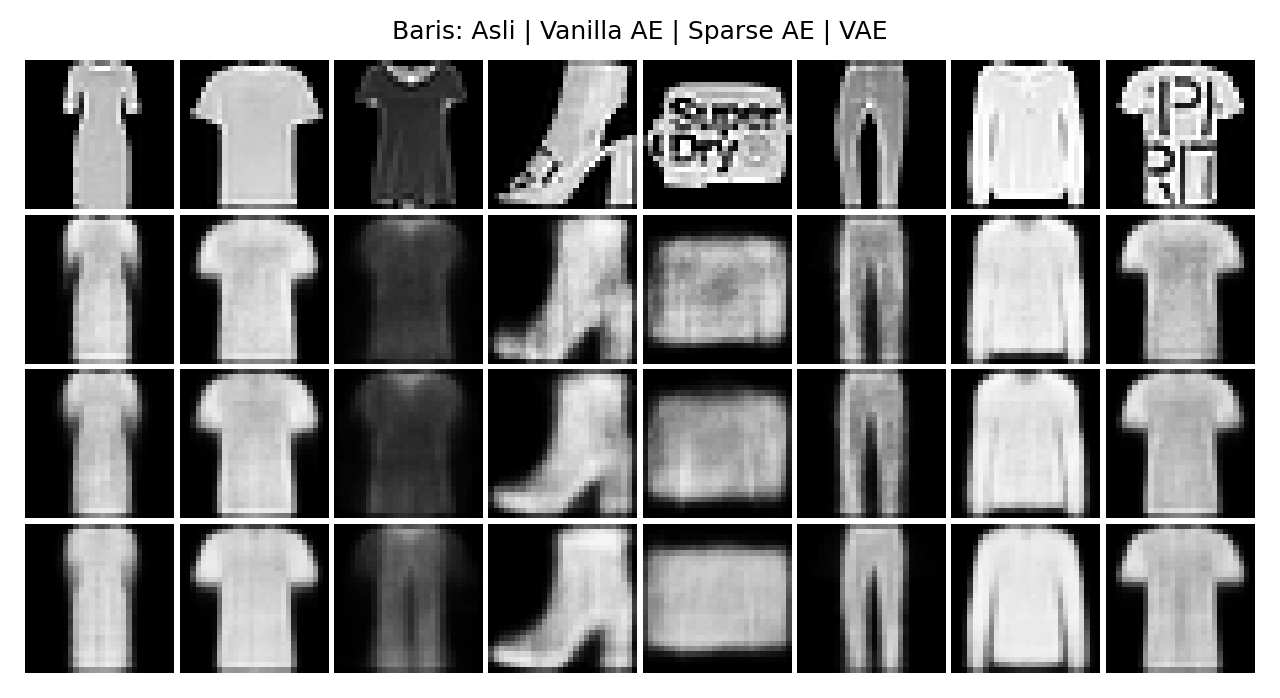

outputs/fig2_sampling.png


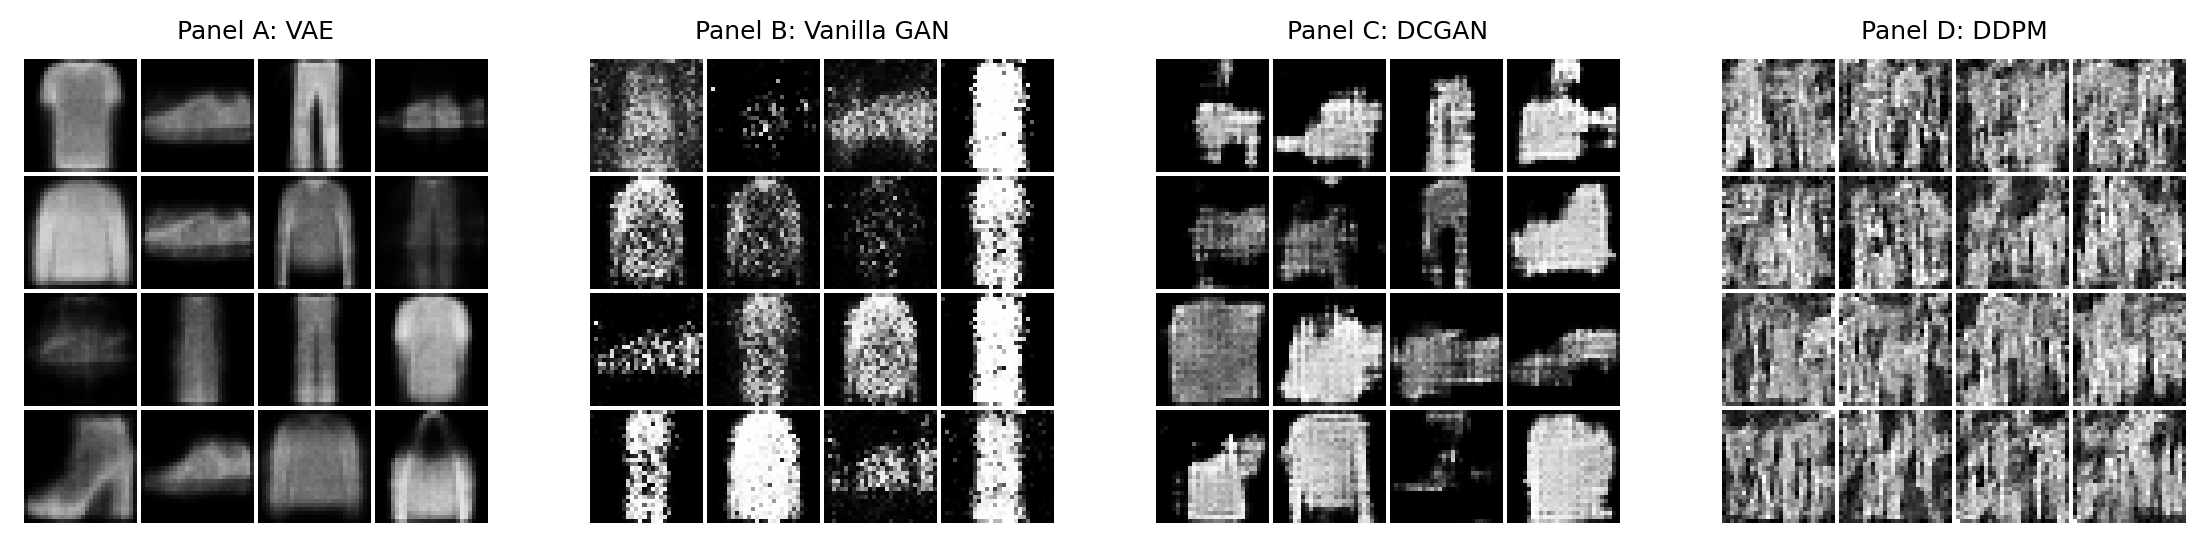

outputs/fig3_mlp_limits.png


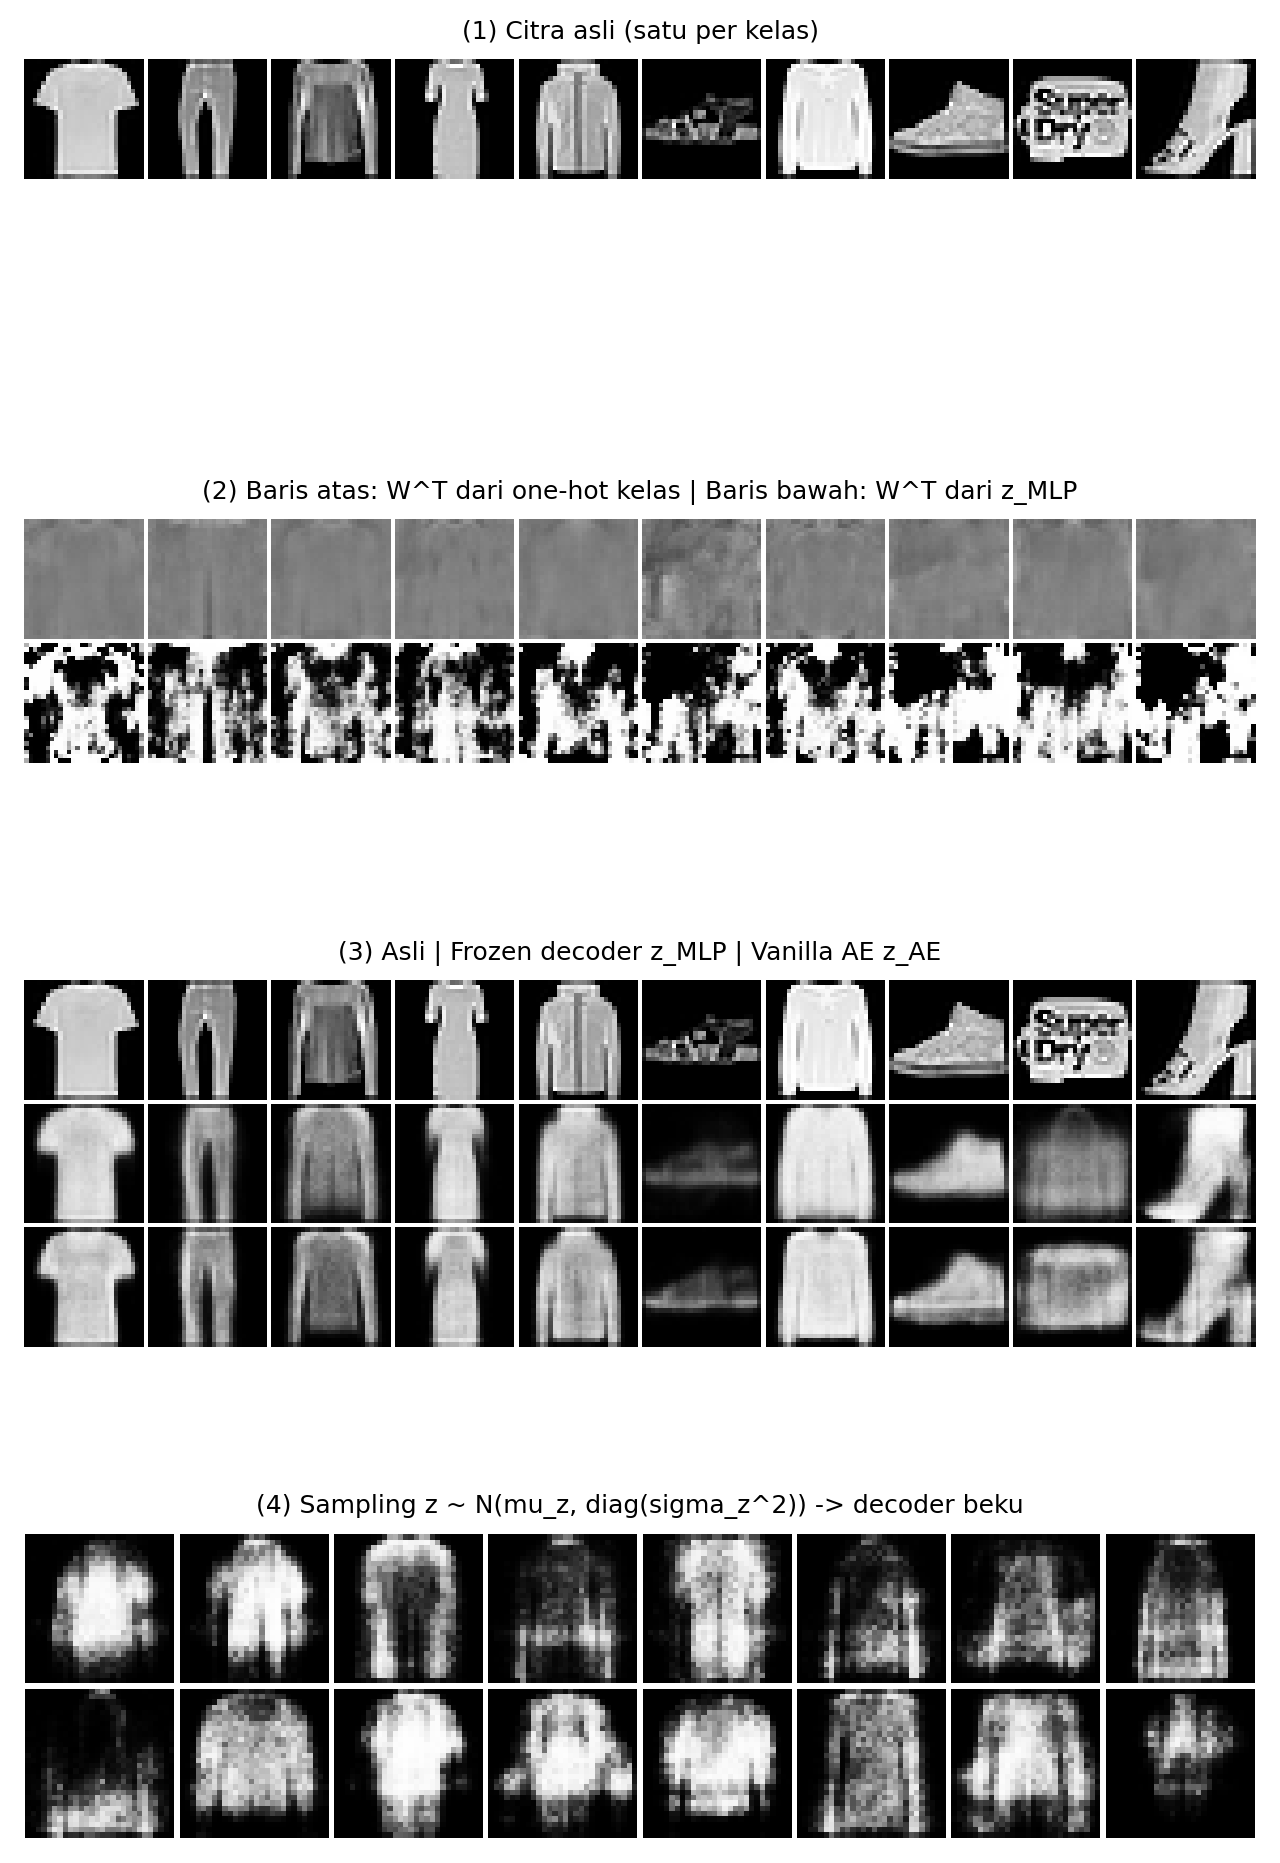

outputs/fig4_interpolation.png


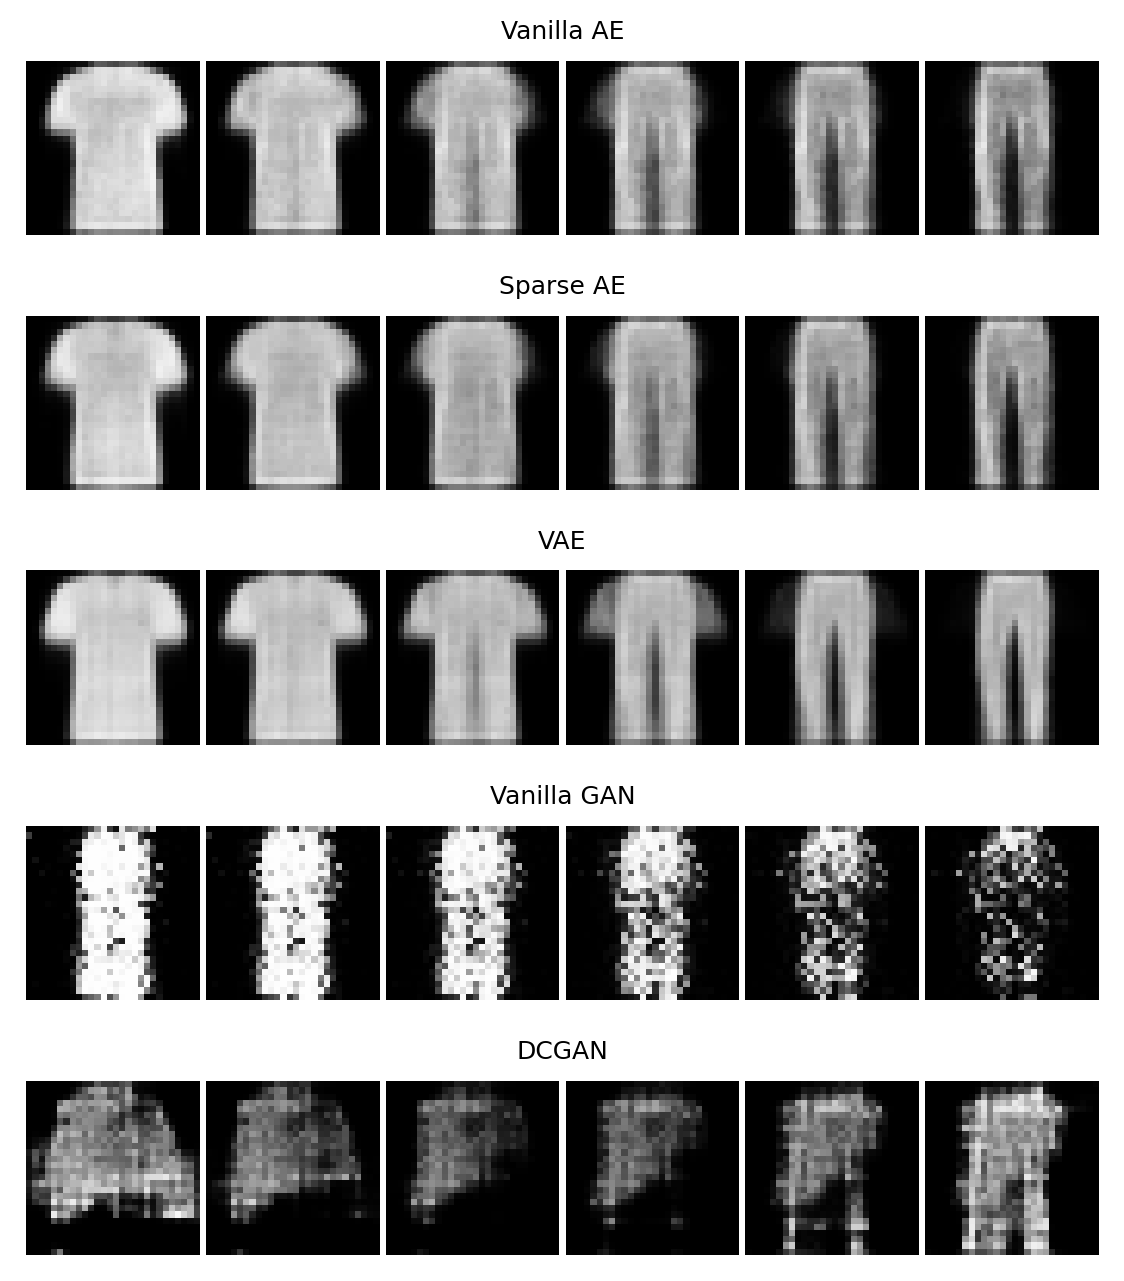

outputs/fig5_loss_ddpm.png


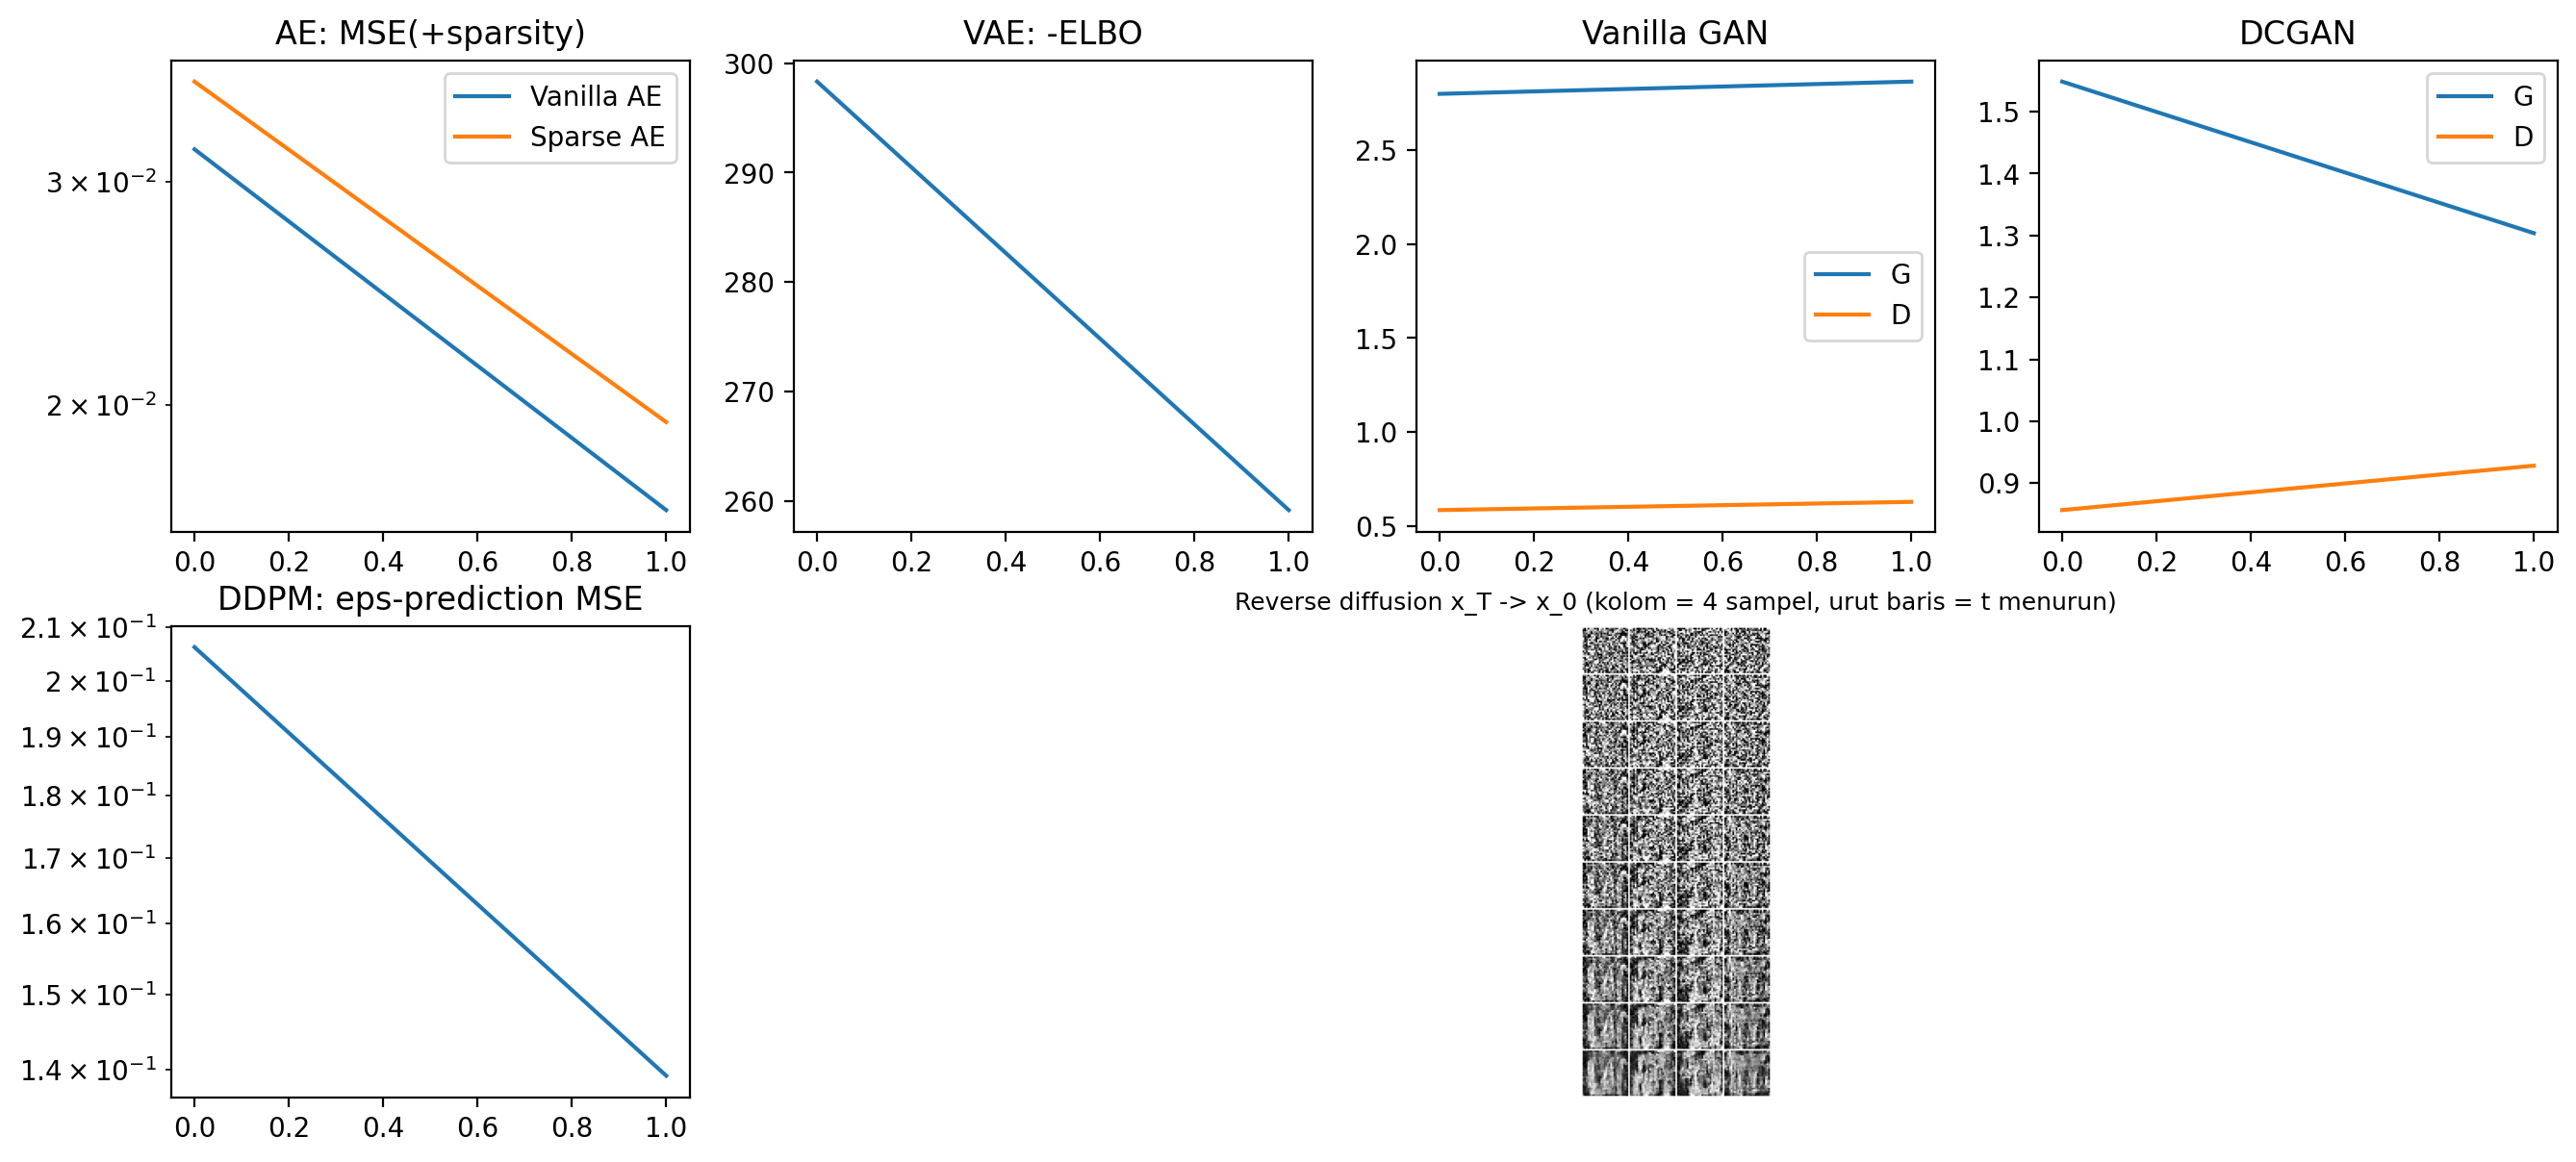

{
  "Vanilla AE": {
    "mse": 0.015562522768974305,
    "psnr": 18.73434725516183,
    "ssim": 0.7178970187732152,
    "auroc_anomali_sintetis": 0.7073513865470886,
    "frac_h_nol": 0.47203513979911804,
    "latency_ms_batch64": 0.2137167999990197,
    "train_s_per_epoch": 6.78078293800354
  },
  "Sparse AE": {
    "mse": 0.017293597391673497,
    "psnr": 18.28638795689174,
    "ssim": 0.68912626348223,
    "auroc_anomali_sintetis": 0.7123692035675049,
    "frac_h_nol": 0.8852421641349792,
    "latency_ms_batch64": 0.18900014999871928,
    "train_s_per_epoch": 7.396985292434692
  },
  "VAE": {
    "mse": 0.026258745431900023,
    "psnr": 16.30101926967076,
    "ssim": 0.642954286302839,
    "auroc_anomali_sintetis": 0.6932597160339355,
    "fid": 151.9535675048828,
    "latency_ms_batch64": 0.168740499998421,
    "train_s_per_epoch": 7.263543605804443
  },
  "Vanilla GAN": {
    "fid": 250.5042724609375,
    "latency_ms_batch64": 0.2952665000009347,
    "train_s_per_epoch": 8.8823657

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import glob, json
from IPython.display import Image, display
for f in sorted(glob.glob('outputs/*.png')):
    print(f); display(Image(f))
print(open('outputs/results.json').read()); print(open('outputs/mlp_limits.json').read())
!zip -qr outputs.zip outputs
from google.colab import files
files.download('outputs.zip')